<a href="https://colab.research.google.com/github/kameshM2007/college-placement-and-skill-analysis1/blob/main/EDA%20ASSIGNMENT%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# COLLEGE PLACEMENT & SKILL ANALYSIS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")

print("College Placement and Skill Analysis")
print("Libraries imported successfully!")

College Placement and Skill Analysis
Libraries imported successfully!


# **Load the Student Dataset**

In [ ]:
# Upload your student placement CSV file
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    df = pd.read_csv(filename)
    print("Dataset loaded:", filename)

else:
    print("No file uploaded.")

# Required columns for the project:
# Student_ID, CGPA, Technical_Skills, Communication_Skills,
# Aptitude_Score, Internship, Projects, Placement_Status

if 'df' not in globals():
    df = pd.DataFrame({
        'Student_ID': range(1, 201),
        'CGPA': np.round(np.random.uniform(5.0, 10.0, 200), 2),
        'Technical_Skills': np.random.randint(30, 101, 200),
        'Communication_Skills': np.random.randint(30, 101, 200),
        'Aptitude_Score': np.random.randint(30, 101, 200),
        'Internship': np.random.choice(['Yes', 'No'], 200),
        'Projects': np.random.randint(0, 7, 200)
    })

    # Demonstration-only placement labels
    score = (
        df['CGPA'] * 7
        + df['Technical_Skills'] * 0.25
        + df['Communication_Skills'] * 0.15
        + df['Aptitude_Score'] * 0.20
        + (df['Internship'] == 'Yes') * 8
        + df['Projects'] * 1.5
    )

    df['Placement_Status'] = np.where(
        score >= 65, 'Placed', 'Not Placed'
    )

print("\nDataset Preview:")
display(df.head(10))

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Saving college_placement_skill_dataset.csv to college_placement_skill_dataset (1).csv
Dataset loaded: college_placement_skill_dataset (1).csv

Dataset Preview:


,Student_ID,CGPA,Technical_Skills,Communication_Skills,Aptitude_Score,Internship,Projects,Placement_Status
0,STU001,8.87,100,73,30,No,5,Placed
1,STU002,7.19,85,85,51,No,1,Placed
2,STU003,9.29,52,82,66,No,2,Placed
3,STU004,8.49,98,39,95,No,2,Placed
4,STU005,5.47,65,88,82,No,1,Placed
5,STU006,9.88,65,68,85,No,1,Placed
6,STU007,8.81,60,52,68,Yes,2,Placed
7,STU008,8.93,40,66,37,No,6,Placed
8,STU009,5.64,96,98,57,No,0,Placed
9,STU010,7.25,30,90,100,Yes,1,Placed



Dataset Shape: (200, 8)

Column Names:
['Student_ID', 'CGPA', 'Technical_Skills', 'Communication_Skills', 'Aptitude_Score', 'Internship', 'Projects', 'Placement_Status']


# **Data Cleaning and Exploratory Data Analysis:**

In [ ]:
# ==========================================
# DATA CLEANING
# ==========================================

print("Missing Values Before Cleaning:")
display(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Convert numerical columns to numeric format
numeric_cols = [
    'CGPA',
    'Technical_Skills',
    'Communication_Skills',
    'Aptitude_Score',
    'Projects'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill missing numeric values with the median
for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
categorical_cols = ['Internship', 'Placement_Status']

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

print("\nMissing Values After Cleaning:")
display(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include='all'))

Missing Values Before Cleaning:


,0
Student_ID,0
CGPA,0
Technical_Skills,0
Communication_Skills,0
Aptitude_Score,0
Internship,0
Projects,0
Placement_Status,0


Duplicate Rows: 0

Missing Values After Cleaning:


,0
Student_ID,0
CGPA,0
Technical_Skills,0
Communication_Skills,0
Aptitude_Score,0
Internship,0
Projects,0
Placement_Status,0



Statistical Summary:


,Student_ID,CGPA,Technical_Skills,Communication_Skills,Aptitude_Score,Internship,Projects,Placement_Status
count,200,200.000000,200.000000,200.000000,200.000000,200,200.000000,200
unique,200,NaN,NaN,NaN,NaN,2,NaN,1
top,STU001,NaN,NaN,NaN,NaN,No,NaN,Placed
freq,1,NaN,NaN,NaN,NaN,115,NaN,200
mean,NaN,7.468850,65.570000,66.870000,64.125000,NaN,2.785000,NaN
std,NaN,1.411533,21.643876,19.869248,20.868802,NaN,2.017206,NaN
min,NaN,5.040000,30.000000,30.000000,30.000000,NaN,0.000000,NaN
25%,NaN,6.260000,46.000000,50.750000,45.750000,NaN,1.000000,NaN
50%,NaN,7.395000,65.500000,68.000000,66.000000,NaN,3.000000,NaN
75%,NaN,8.732500,86.000000,84.000000,80.500000,NaN,5.000000,NaN


# **PLACEMENT STATISTICS**

Total Students: 200
Placed Students: 200
Other Placement Statuses: 0
Placement Percentage: 100.00%


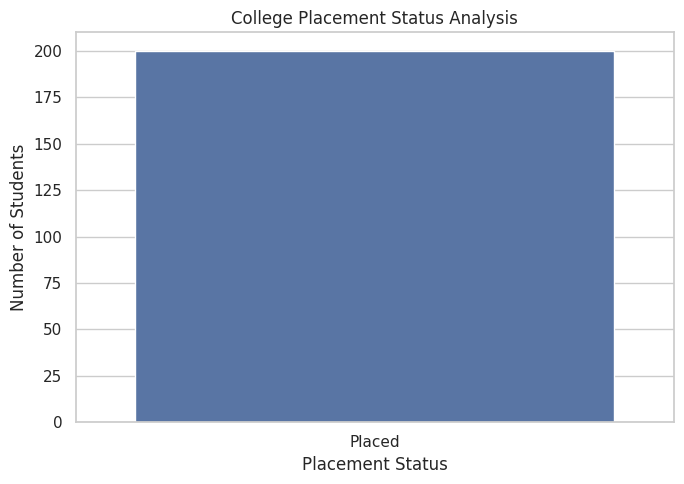

In [ ]:
# ==========================================
# PLACEMENT STATISTICS
# ==========================================

if 'Placement_Status' not in df.columns:
    raise ValueError("Dataset must contain Placement_Status.")

placement_counts = df['Placement_Status'].value_counts()

total_students = len(df)

placed_students = (
    df['Placement_Status'].astype(str).str.strip().str.lower()
    == 'placed'
).sum()

not_placed_students = total_students - placed_students

placement_percentage = (
    placed_students / total_students * 100
    if total_students > 0 else 0
)

print("Total Students:", total_students)
print("Placed Students:", placed_students)
print("Other Placement Statuses:", not_placed_students)
print(f"Placement Percentage: {placement_percentage:.2f}%")

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='Placement_Status',
    hue='Placement_Status',
    legend=False
)

plt.title("College Placement Status Analysis")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# **SKILL ANALYSIS**



Average Student Skill Scores:


,Average Score
Technical_Skills,65.570
Communication_Skills,66.870
Aptitude_Score,64.125


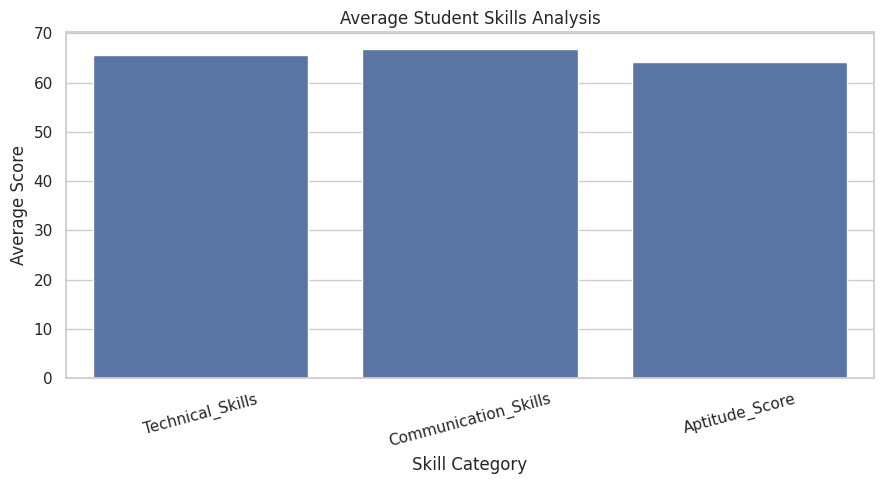

In [ ]:
# ==========================================
# SKILL ANALYSIS
# ==========================================

skill_columns = [
    'Technical_Skills',
    'Communication_Skills',
    'Aptitude_Score'
]

available_skills = [
    col for col in skill_columns if col in df.columns
]

if available_skills:
    skill_averages = df[available_skills].mean()

    print("Average Student Skill Scores:")
    display(skill_averages.to_frame("Average Score"))

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=skill_averages.index,
        y=skill_averages.values
    )

    plt.title("Average Student Skills Analysis")
    plt.xlabel("Skill Category")
    plt.ylabel("Average Score")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

# **Compare Skills of Placed and Non-Placed Students**

Average Skills by Placement Status:


,Technical_Skills,Communication_Skills,Aptitude_Score
Placement_Status,,,
Placed,65.57,66.87,64.12


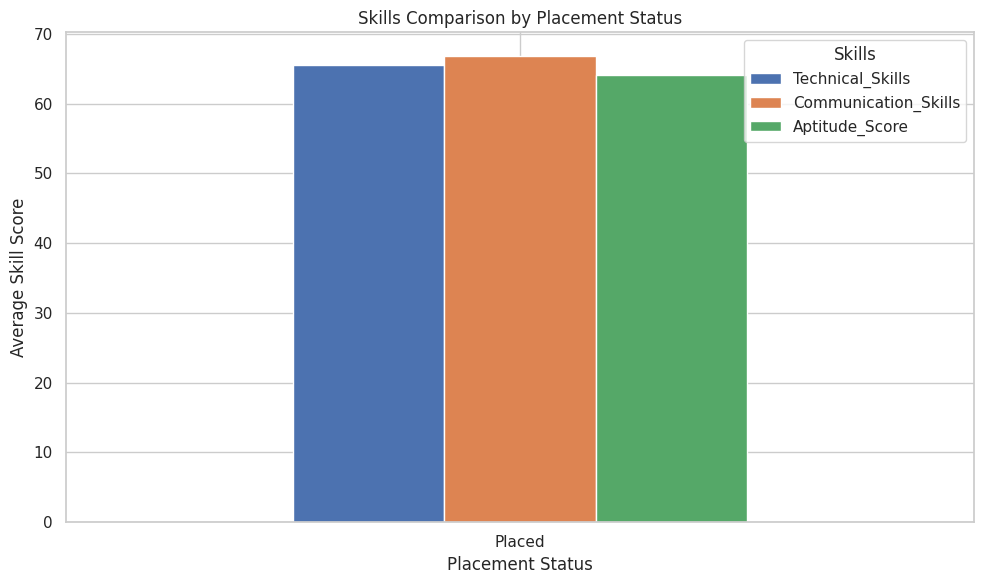

In [ ]:
# ==========================================
# PLACEMENT VS SKILLS
# ==========================================

if available_skills and 'Placement_Status' in df.columns:

    comparison = df.groupby(
        'Placement_Status'
    )[available_skills].mean()

    print("Average Skills by Placement Status:")
    display(comparison.round(2))

    comparison.plot(
        kind='bar',
        figsize=(10, 6)
    )

    plt.title("Skills Comparison by Placement Status")
    plt.xlabel("Placement Status")
    plt.ylabel("Average Skill Score")
    plt.xticks(rotation=0)
    plt.legend(title="Skills")
    plt.tight_layout()
    plt.show()

# **CGPA vs Placement Analysis**

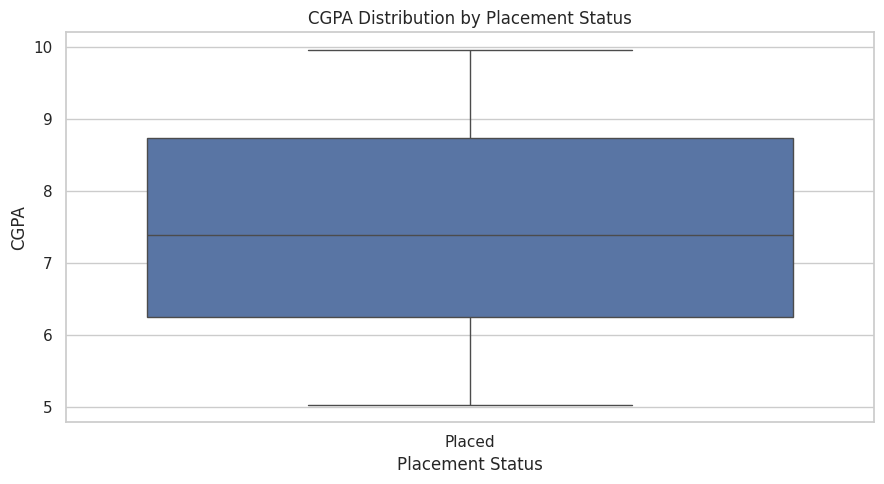

,mean,median,min,max
Placement_Status,,,,
Placed,7.47,7.4,5.04,9.96


In [ ]:
# ==========================================
# CGPA ANALYSIS
# ==========================================

if 'CGPA' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x='Placement_Status',
        y='CGPA',
        hue='Placement_Status',
        legend=False
    )

    plt.title("CGPA Distribution by Placement Status")
    plt.xlabel("Placement Status")
    plt.ylabel("CGPA")
    plt.tight_layout()
    plt.show()

    cgpa_analysis = df.groupby(
        'Placement_Status'
    )['CGPA'].agg(['mean', 'median', 'min', 'max'])

    display(cgpa_analysis.round(2))

# **Correlation Heatmap**

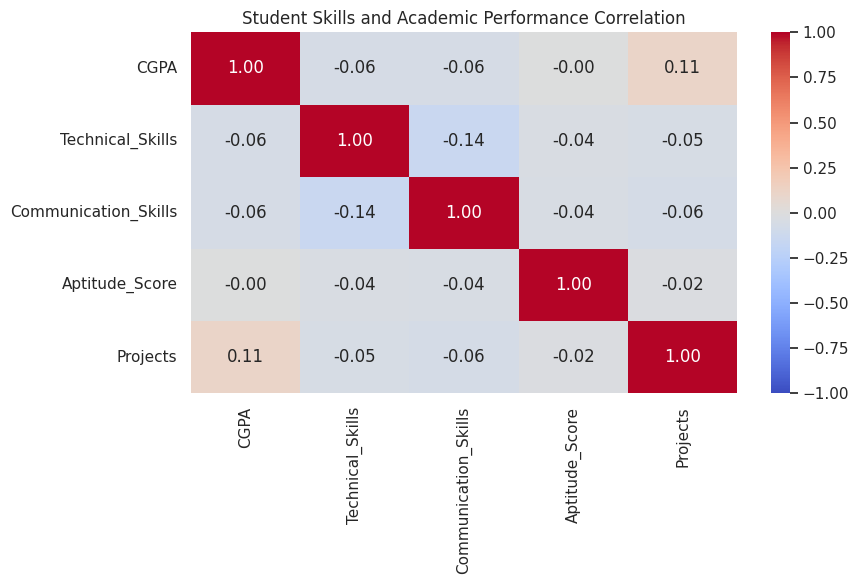

In [ ]:
# ==========================================
# CORRELATION ANALYSIS
# ==========================================

correlation_columns = [
    col for col in [
        'CGPA',
        'Technical_Skills',
        'Communication_Skills',
        'Aptitude_Score',
        'Projects'
    ]
    if col in df.columns
]

if len(correlation_columns) >= 2:

    correlation_matrix = df[correlation_columns].corr()

    plt.figure(figsize=(9, 6))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap='coolwarm',
        fmt='.2f',
        vmin=-1,
        vmax=1
    )

    plt.title("Student Skills and Academic Performance Correlation")
    plt.tight_layout()
    plt.show()

# **Internship and Placement Analysis**

Internship vs Placement:


Placement_Status,Placed
Internship,
No,115
Yes,85


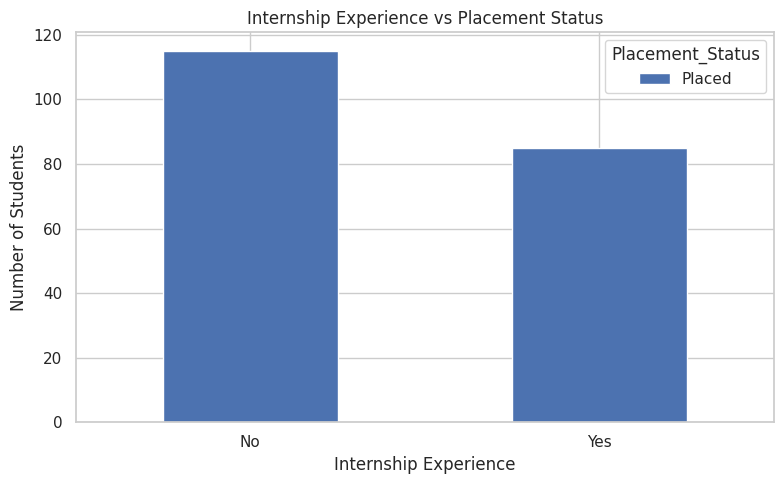

In [ ]:
# ==========================================
# INTERNSHIP ANALYSIS
# ==========================================

if 'Internship' in df.columns:

    internship_counts = pd.crosstab(
        df['Internship'],
        df['Placement_Status']
    )

    print("Internship vs Placement:")
    display(internship_counts)

    internship_counts.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5)
    )

    plt.title("Internship Experience vs Placement Status")
    plt.xlabel("Internship Experience")
    plt.ylabel("Number of Students")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Optional Machine Learning — Placement Prediction

In [ ]:
# ==========================================
# MACHINE LEARNING MODEL
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

target = 'Placement_Status'

feature_candidates = [
    'CGPA',
    'Technical_Skills',
    'Communication_Skills',
    'Aptitude_Score',
    'Internship',
    'Projects'
]

features = [c for c in feature_candidates if c in df.columns]

model_df = df[features + [target]].dropna().copy()

X = model_df[features]
y = model_df[target].astype(str)

if y.nunique() < 2:
    print("The dataset needs at least two placement-status classes.")

elif y.value_counts().min() < 2:
    print("Each class needs at least two records for a stratified split.")

else:
    numeric_features = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_features = [
        c for c in X.columns if c not in numeric_features
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', 'passthrough', numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'),
             categorical_features)
        ]
    )

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight='balanced'
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print(
        f"Model Accuracy: "
        f"{accuracy_score(y_test, predictions) * 100:.2f}%"
    )

    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        xticks_rotation='vertical'
    )

    plt.title("Placement Prediction - Confusion Matrix")
    plt.tight_layout()
    plt.show()

The dataset needs at least two placement-status classes.
